In [1]:
import pandas as pd
import numpy as np

# Load the Custom Dataset We Created
print("Loading data...")
df = pd.read_csv('../data/processed/custom_readmission_dataset.csv')

# Convert '?' Signs in Clinical Data to Real Missing Values (NaN)
df.replace('?', np.nan, inplace=True)

# Drop Columns That Are Useless or Contain Too Many Missing Values
cols_to_drop = ['weight', 'payer_code', 'medical_specialty', 'encounter_id', 'patient_nbr']
df.drop(columns=[col for col in cols_to_drop if col in df.columns], inplace=True)

# Create Readmission_Risk as Binary 1 and 0
# '<30' (Patients readmitted before 30 days) = 1 (High-Risk Class)
# '>30' or 'NO' = 0 (Low-Risk Class)
df['Readmission_Risk'] = df['readmitted'].apply(lambda x: 1 if x == '<30' else 0)

# Drop the Original Readmitted Column
df.drop(columns=['readmitted'], inplace=True, errors='ignore')

# Save the Cleaned Dataset
clean_output_path = '../data/processed/cleaned_dataset.csv'
df.to_csv(clean_output_path, index=False)

print("-" * 50)
print("Data cleaning completed and 'Readmission_Risk' target variable created!")
print(f"Number of Remaining Clean Columns: {df.shape[1]}")
print("\nRisk Distribution (1: High-Risk, 0: Low-Risk):")
print(df['Readmission_Risk'].value_counts())

Loading data...
--------------------------------------------------
Data cleaning completed and 'Readmission_Risk' target variable created!
Number of Remaining Clean Columns: 82

Risk Distribution (1: High-Risk, 0: Low-Risk):
Readmission_Risk
0    90409
1    11357
Name: count, dtype: int64


DATA ANALYSIS AND VISUALIZATION STARTING ---


C:\Users\user\AppData\Local\Temp\ipykernel_9896\4272486513.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=cleaned_df, x=target_col, palette='viridis')


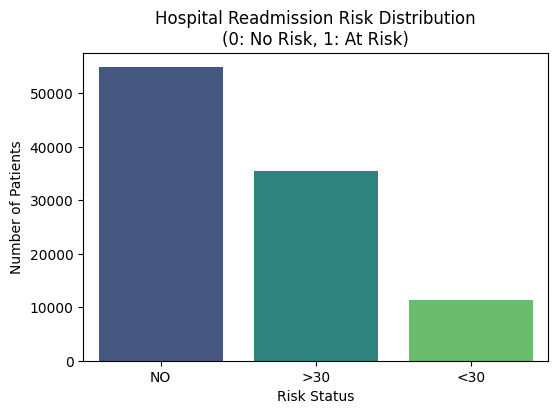

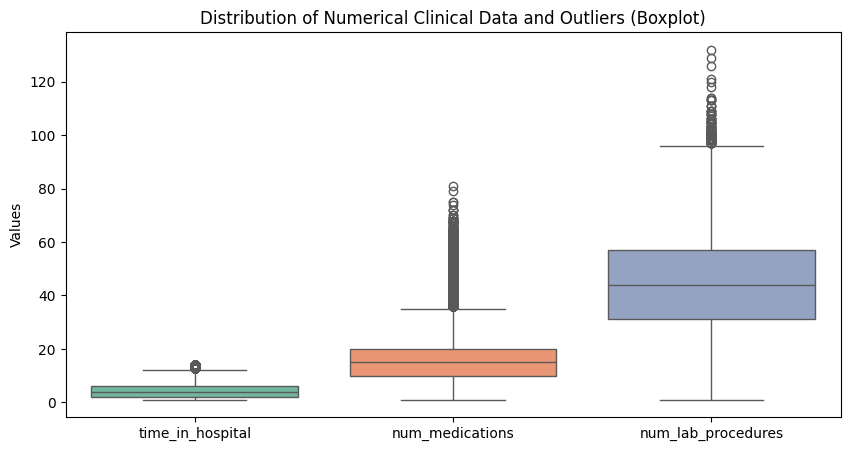

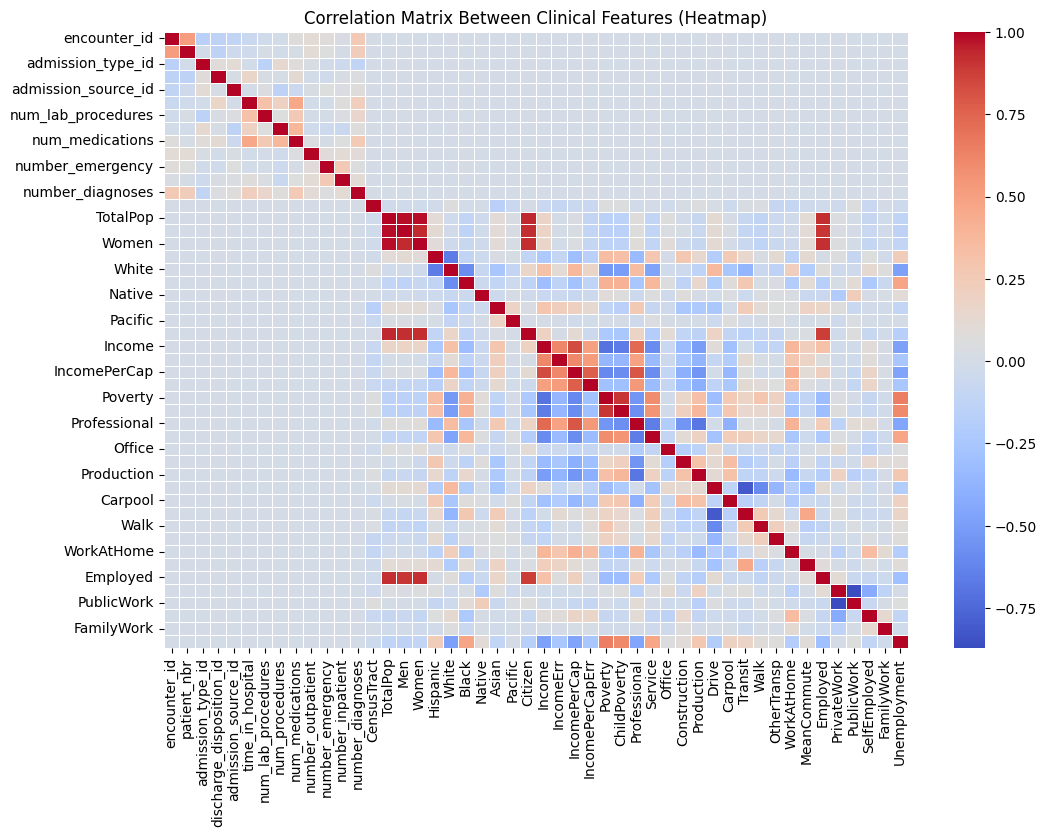

Figures 2, 3, and 4 successfully plotted for the report!


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("DATA ANALYSIS AND VISUALIZATION STARTING ---")

# Reading the data to avoid depending on variables in memory
cleaned_df = pd.read_csv('../data/processed/custom_readmission_dataset.csv')

# Determining the target column
target_col = 'readmitted_risk' if 'readmitted_risk' in cleaned_df.columns else 'readmitted'

# 1. Distribution of the Target Variable
plt.figure(figsize=(6, 4))
sns.countplot(data=cleaned_df, x=target_col, palette='viridis')
plt.title("Hospital Readmission Risk Distribution\n(0: No Risk, 1: At Risk)")
plt.xlabel("Risk Status")
plt.ylabel("Number of Patients")
plt.show()

# 2. Box Plot of Numerical Data
plt.figure(figsize=(10, 5))
sns.boxplot(data=cleaned_df[['time_in_hospital', 'num_medications', 'num_lab_procedures']], palette='Set2')
plt.title("Distribution of Numerical Clinical Data and Outliers (Boxplot)")
plt.ylabel("Values")
plt.show()

# 3. Correlation Matrix
plt.figure(figsize=(12, 8))
# Selecting only numerical columns and examining their correlations
numeric_cols = cleaned_df.select_dtypes(include=['int64', 'float64']).columns
correlation_matrix = cleaned_df[numeric_cols].corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title("Correlation Matrix Between Clinical Features (Heatmap)")
plt.show()

print("Figures 2, 3, and 4 successfully plotted for the report!")